# Paso 15 · QFT y sistemas no lineales (con Python)

Notebook del **Paso 15**: una no linealidad acotada en amplitud se comporta como un parámetro incierto. Simulamos la planta *no lineal* con el diseño del Paso 9 y vemos cuándo la equivalencia vale.

| Concepto matemático | Concepto de programación |
|---|---|
| sector $a\in[a_1,a_2]$ | envolvente de respuestas lineales (`signal.step`) |
| integración de la planta no lineal | Runge–Kutta 4 escrito a mano |
| saturación ⇒ $K$ equivalente $\beta K$ | barrido de $K_{\min}$ y cuenta de fallos |
| fricción de Coulomb ⇒ perturbación $f_c/K$ | comparar simulación con cota teórica |
| cuantización $\pm q/2$ | cota $\|t\|_1 q/2$ |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
from scipy import signal
from nbhelp import db, AZUL, NARANJA, TINTA, GRIS, VERDE, MORADO
from qft import KS, AS, P, spec_ok, TU, TL
G9 = lambda s: 5*(1 + s/2)/(1 + s/20)          # diseño del paso 9 (con el prefiltro F = 1.2/(s+1.2))

def simnl(K, a, R, T=8.0, dt=2e-3, c=0.0, umax=1e9, fc=0.0, dist=0.0):
    """Lazo no lineal (RK4).  x1' = x2 ;  x2' = -(a x2 + c x2^3) - fc tanh(x2/0.01) + K sat(u)
    Controlador G(s) = 50 - 900/(s+20) (= 50(s+2)/(s+20)) y prefiltro F = 1.2/(s+1.2); escalón de altura R."""
    N = int(T/dt)
    def f(st):
        x1, x2, xc, rf = st; e = rf - x1; u = 50*e - 900*xc; us = min(max(u, -umax), umax)
        return np.array([x2, -(a*x2 + c*x2**3) - fc*np.tanh(x2/0.01) + K*us + dist*K, e - 20*xc, 1.2*(R - rf)])
    st = np.zeros(4); Y = np.zeros(N); V = np.zeros(N)
    for i in range(N):
        Y[i] = st[0]; V[i] = st[1]
        k1 = f(st); k2 = f(st + dt/2*k1); k3 = f(st + dt/2*k2); k4 = f(st + dt*k3); st = st + dt/6*(k1 + 2*k2 + 2*k3 + k4)
    return np.arange(N)*dt, Y, V
t, y, v = simnl(5, 1, 1.0)
print(f"prueba (lineal, K=5, a=1): y(8 s) = {y[-1]:.4f}, |v| máx = {abs(v).max():.2f}")

prueba (lineal, K=5, a=1): y(8 s) = 0.9999, |v| máx = 1.18


## 1. La idea: una no linealidad es otra forma de incertidumbre

Una planta no lineal responde distinto según la **amplitud**. Si las amplitudes están acotadas (por la referencia, la perturbación, los límites físicos), la no linealidad se comporta como un **parámetro incierto** en un intervalo, y ya sabemos hacer templates, bounds y loop shaping.

| No linealidad | Equivale a |
|---|---|
| Amortiguamiento | sector $a\in[a_1,a_2]$ |
| Saturación | ganancia $K$ más baja |
| Fricción de Coulomb | perturbación acotada |

**Condición**: la equivalencia vale mientras las amplitudes estén dentro de lo supuesto. Fuera no hay garantía: al final siempre se simula el lazo no lineal.

## 2. Ejemplo 1: amortiguamiento no lineal ⇒ sector

$\dot x_2=-\varphi(x_2)+Ku$ con $\varphi(v)=v+0.5\,v^3$. Para $|v|\le2$: $v\le\varphi(v)\le3v$, es decir, un sector $[1,3]$ = nuestra familia $a\in[1,3]$.

In [3]:
v = np.linspace(0.01, 2, 400); ratio_phi = (v + 0.5*v**3)/v
print(f"φ(v)/v para 0 < v ≤ 2: de {ratio_phi.min():.2f} a {ratio_phi.max():.2f}  ->  sector [1, 3]")
for vmax in (1, 2, 3):
    print(f"|v| ≤ {vmax}: sector [1, {1 + 0.5*vmax**2:.2f}]")

φ(v)/v para 0 < v ≤ 2: de 1.00 a 3.00  ->  sector [1, 3]
|v| ≤ 1: sector [1, 1.50]
|v| ≤ 2: sector [1, 3.00]
|v| ≤ 3: sector [1, 5.50]


La envolvente de las respuestas *lineales* de la familia con el diseño del Paso 9 (todas las plantas $K\in[1,5]$, $a\in[1,3]$), y la distancia a la que se salen las respuestas no lineales:

In [4]:
tt = np.arange(4000)*2e-3
def cl_tf(K, a):
    nL = np.polymul([50, 100], [K]); dL = np.polymul([1, 20], [1, a, 0])
    return np.polymul(nL, [1.2]), np.polymul(np.polyadd(dL, nL), [1, 1.2])

resp = np.array([signal.step(cl_tf(K, a), T=tt)[1] for K in KS[::2] for a in AS[::2]])
lo, hi = resp.min(0), resp.max(0)
fuera = lambda y, R: max(0.0, float((lo - y/R).max()), float((y/R - hi).max()))

print(f"{'R':>4} {'máx|v| (K=1)':>14} {'máx|v| (K=5)':>14} {'fuera envolvente (K=1)':>24}")
for R in (0.5, 1, 2, 4, 6):
    _, y1, v1 = simnl(1, 1.0, R, c=0.5); _, y5, v5 = simnl(5, 1.0, R, c=0.5)
    print(f"{R:>4} {abs(v1).max():>14.2f} {abs(v5).max():>14.2f} {fuera(y1, R):>24.4f}")

   R   máx|v| (K=1)   máx|v| (K=5)   fuera envolvente (K=1)
 0.5           0.38           0.58                   0.0001


   1           0.73           1.13                   0.0004
   2           1.32           2.07                   0.0012


   4           2.14           3.39                   0.0018
   6           2.70           4.29                   0.0657


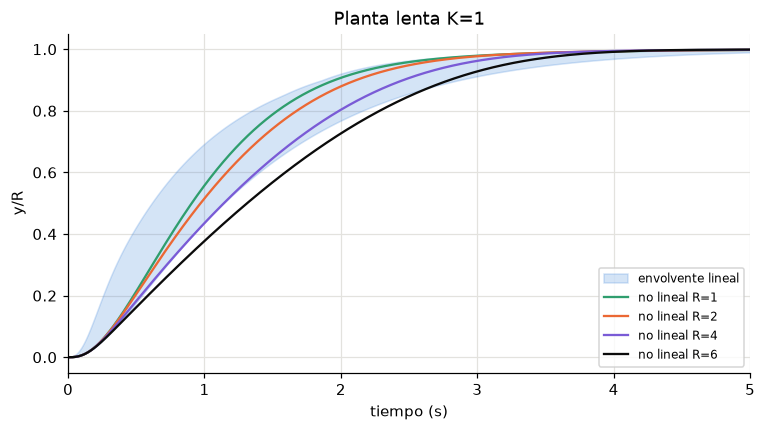

In [5]:
fig, ax = plt.subplots(figsize=(8, 4)); ax.fill_between(tt, lo, hi, color=AZUL, alpha=0.2, label="envolvente lineal")
for R, c in ((1, VERDE), (2, NARANJA), (4, MORADO), (6, TINTA)):
    _, y, _ = simnl(1, 1.0, R, c=0.5); ax.plot(tt, y/R, color=c, label=f"no lineal R={R}")
ax.set_xlim(0, 5); ax.set_xlabel("tiempo (s)"); ax.set_ylabel("y/R"); ax.legend(fontsize=8, loc="lower right"); ax.set_title("Planta lenta K=1"); plt.show()

Hasta $R=4$ las respuestas quedan en la envolvente (a lo sumo $\sim0.002$ fuera); con $R=6$ la planta lenta se sale por abajo. El diseño se hace para un **rango de amplitudes**, no para «cualquier» señal.

## 3. Ejemplo 2: saturación ⇒ ganancia equivalente más baja

Para una señal de amplitud $A>u_{\max}$, $N(A)\approx u_{\max}/A$: $K$ se comporta como $K\,N\in[\beta K,K]$ y $K_{\min}$ baja a $\beta K_{\min}$. ¿Hasta cuánto aguanta el diseño del Paso 9?

In [6]:
W = np.logspace(-2, np.log10(60), 300)
def n_fallos(Kmin):
    Ks = np.linspace(Kmin, 5, 17); n = 0; primero = None
    for w in W:
        fam = np.array([P(w, K, a) for K in Ks for a in AS]); p0 = P(w, Kmin, 1.0)
        ok = all(spec_ok(w, np.array(G9(1j*w)*p0), fam/p0))
        if not ok:
            n += 1; primero = primero if primero else w
    return n, primero

print(f"{'K_min':>6} {'frecuencias que incumplen (de 300)':>36}  primera")
for Kmin in (1, 0.8, 0.6, 0.5, 0.4, 0.3):
    n, p = n_fallos(Kmin); print(f"{Kmin:>6} {n:>36}  {('ω = %.2f' % p) if p else '-'}")

 K_min   frecuencias que incumplen (de 300)  primera
     1                                    0  -
   0.8                                   11  ω = 0.44


   0.6                                   32  ω = 0.33
   0.5                                   46  ω = 0.27
   0.4                                  159  ω = 0.01


   0.3                                  163  ω = 0.01


Primer fallo con $K_{\min}=0.8$: el **rechazo de perturbación** $|S|\le W_d$ (menos ganancia, menos rechazo). Ahora la planta lenta con saturación real:

In [7]:
print(f"{'umax':>6} {'fuera de la envolvente (R=1)':>30}   K=1,a=1 | K=1,a=3")
for um in (1e9, 2, 1, 0.5):
    d1 = fuera(simnl(1, 1.0, 1.0, umax=um)[1], 1.0); d3 = fuera(simnl(1, 3.0, 1.0, umax=um)[1], 1.0)
    print(f"{('sin' if um > 100 else um):>6} {'':>30}   {d1:.3f}   | {d3:.3f}")
# solo importa umax/R:
y_a = simnl(1, 1.0, 2.0, umax=2)[1]/2; y_b = simnl(1, 1.0, 1.0, umax=1)[1]
print("R=2,umax=2  frente a  R=1,umax=1 (misma curva normalizada):", np.allclose(y_a, y_b, atol=1e-6))

  umax   fuera de la envolvente (R=1)   K=1,a=1 | K=1,a=3
   sin                                  0.000   | 0.000


     2                                  0.001   | 0.027
     1                                  0.093   | 0.245


   0.5                                  0.277   | 0.496
R=2,umax=2  frente a  R=1,umax=1 (misma curva normalizada): True


Solo importa el cociente $u_{\max}/R$. Con $K=5$ casi no importaba (Paso 12); con $K=1$ **sí**.

## 4. Ejemplo 3: fricción de Coulomb ⇒ perturbación acotada

$\dot x_2=-a\,x_2-f_c\,\mathrm{sign}(x_2)+Ku$: una fuerza constante $f_c$ opuesta al movimiento = perturbación de amplitud $f_c/K$ en la entrada. Con $G(0)=5$ la planta se detiene cuando $K\,G(0)|e|\le f_c$, es decir $|e|\le f_c/(5K)$.

In [8]:
print(f"{'K':>3} {'fc':>5} {'error a 20 s':>14} {'cota fc/(5K)':>14}")
for K in (1, 5):
    for fc in (0.1, 0.5, 1.0):
        _, y, _ = simnl(K, 1.0, 1.0, T=20.0, fc=fc); e = 1 - y[-1]
        print(f"{K:>3} {fc:>5} {e:>14.4f} {fc/(5*K):>14.4f}   {'dentro' if e <= fc/(5*K) + 1e-3 else 'FUERA'}")

  K    fc   error a 20 s   cota fc/(5K)


  1   0.1         0.0000         0.0200   dentro


  1   0.5         0.0195         0.1000   dentro


  1   1.0         0.0794         0.2000   dentro


  5   0.1         0.0000         0.0040   dentro


  5   0.5         0.0000         0.0200   dentro


  5   1.0         0.0011         0.0400   dentro


Con fricción suavizada ($f_c\tanh(v/0.01)$) la salida **se arrastra** hacia el valor final. Si se añade acción integral hay que simular con fricción estática (*stick-slip*).

## 5. Otras no linealidades y la discretización

- **Zona muerta** (motor que no se mueve con $|u|<d$): perturbación acotada $\le d$ + pérdida de ganancia a señales pequeñas.
- **Cuantización del sensor** (paso $q$): error $|e|\le q/2$, igual que el umbral del Paso 13 ⇒ $|\Delta y|\le\|t\|_1 q/2$ con $\|t\|_1=1.42$.

In [9]:
Ts = 0.04
nG, dG, _ = signal.cont2discrete(([5.2*28/2.6, 5.2*28], [1, 28]), Ts, method="bilinear"); nG = nG.ravel()
nF, dF, _ = signal.cont2discrete(([1.2], [1, 1.2]), Ts, method="bilinear"); nF = nF.ravel()
def sim_q(K, a, q, N=200):
    A = np.array([[0, 1], [0, -a]]); B = np.array([[0], [K]]); Cm = np.array([[1, 0]])
    Ad, Bd, Cd = signal.cont2discrete((A, B, Cm, [[0]]), Ts, method="zoh")[:3]
    x = np.zeros((2, 1)); y = np.zeros(N); rf_p = r_p = e_p = u_p = 0.0
    for k in range(N):
        yk = float((Cd @ x)[0, 0]); ym = yk if q == 0 else q*np.round(yk/q)         # sensor cuantizado
        rf = -dF[1]*rf_p + nF[0]*(1 + r_p); e = rf - ym; u = -dG[1]*u_p + nG[0]*e + nG[1]*e_p
        y[k] = yk; x = Ad @ x + Bd*u; rf_p, r_p, e_p, u_p = rf, 1, e, u
    return y

esq = [(1, 1), (1, 3), (5, 1), (5, 3)]
print(f"{'q':>6} {'desviación de y medida':>24} {'cota 1.42·q/2':>15}")
for q in (0.01, 0.05, 0.10):
    d = max(np.abs(sim_q(K, a, q) - sim_q(K, a, 0)).max() for K, a in esq)
    print(f"{q:>6} {d:>24.4f} {1.424*q/2:>15.4f}")

     q   desviación de y medida   cota 1.42·q/2
  0.01                   0.0055          0.0071
  0.05                   0.0258          0.0356
   0.1                   0.0492          0.0712


## 6. Estabilidad con no linealidades y procedimiento

Los criterios de estabilidad absoluta (círculo, Popov) usan el mismo concepto de sector, pero son conservadores y no dan prestaciones. QFT cubre lo mismo desde el diseño. **Lo que ni el sector ni QFT garantizan**: ciclos límite, *stick-slip* y dependencia de la condición inicial: se buscan **simulando**.

Procedimiento: (1) acotar las amplitudes; (2) traducir cada no linealidad a incertidumbre/perturbación; (3) diseñar con QFT; (4) **simular el lazo no lineal** con los casos extremos.

## 7. Ejercicio del Paso 15

1. Con $u_{\max}=1$ y señal de amplitud $A=2.5$, ¿cuánto vale $\beta$? 2. Con $K=2$, $f_c=0.3$, $G(0)=5$, ¿cota de error? 3. Con sensor de cuantización $q=0.02$, ¿cota de desviación de $y$?

**Tu turno.**

In [10]:
# 1) beta = umax/A    2) |e| <= fc/(G0 K)    3) ||t||_1 q/2
# escribe aquí tu código

In [11]:
print(f"1) β = u_max/A = 1/2.5 = {1/2.5}")
print(f"2) |e| ≤ f_c/(G(0)·K) = 0.3/(5·2) = {0.3/(5*2)}")
print(f"3) ‖t‖₁·q/2 = 1.42·0.01 = {1.424*0.02/2:.4f}  (la desviación medida con q = 0.01 fue 0.0055: la cota es conservadora)")

1) β = u_max/A = 1/2.5 = 0.4
2) |e| ≤ f_c/(G(0)·K) = 0.3/(5·2) = 0.03
3) ‖t‖₁·q/2 = 1.42·0.01 = 0.0142  (la desviación medida con q = 0.01 fue 0.0055: la cota es conservadora)


## 8. Resumen

- Una no linealidad con amplitudes acotadas es incertidumbre: amortiguamiento → **sector**; saturación → **$K$ más baja**; fricción → **perturbación acotada**; cuantización → **ruido acotado**.
- El diseño vale mientras las amplitudes estén en el rango supuesto; fuera, no hay garantía.
- Siempre se **simula** el lazo no lineal con los casos extremos.